## Setup Libraries

In [1]:
!pip install -U 'skorch[pytorch]' && pip install -q -U faiss-gpu-cu12

In [2]:
!pip install -q pytabkit

In [3]:
try:
    from colorama import Fore, Style
except:
    !pip install -q colorama
    from colorama import Fore, Style

%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [4]:
import random
import warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from importlib.metadata import version
from time import time

from sklearn.calibration import CalibrationDisplay
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import KBinsDiscretizer, TargetEncoder
from sklearn.metrics import roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay

import torch
import pytabkit
from pytabkit import (
            Resnet_RTDL_D_Classifier,
            MLP_RTDL_D_Classifier,
            MLP_PLR_D_Classifier,
            TabR_S_D_Classifier,
            FTT_D_Classifier,
)

warnings.filterwarnings('ignore')
print("PyTorch  version:", torch.__version__)
print("PyTabKit version:", version("pytabkit"))

def seed_everything(seed: int):
    print(f"🌱 Seed everything ({seed})")
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

seed_everything(42)

PyTorch  version: 2.11.0+cu130
PyTabKit version: 1.8.0
🌱 Seed everything (42)


In [5]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 9,
    'axes.titlesize': 11,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})

## Load Data

In [6]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH   = "/kaggle/input/competitions/playground-series-s6e11/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    ORIG_PATH = "/kaggle/input/datasets/uditjain13/credit-card-fraud-detection-2026/"
    orig = pd.read_csv(ORIG_PATH+"credit_card_fraud_2026.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")
    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e11 | Credit Card Fraud/_fraud_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig   = pd.read_csv(PATH+"credit_card_fraud_2026.csv")
## =================================================================================
ID = 'id'
TARGET = 'is_fraud'

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name} shape: {df.shape}")

print(f"\nFrame type: {type(train)}")

train_len = len(train)
test_len  = len(test)

n_unique = train.nunique().sort_values()
n_unique

Train shape: (699960, 26)
Test shape: (299984, 25)
Orig shape: (20000, 26)

Frame type: <class 'pandas.core.frame.DataFrame'>


is_new_merchant                      2
is_fraud                             2
is_ai_generated_scam_attempt         2
billing_shipping_mismatch            2
ip_country_mismatch                  2
used_vpn                             2
is_foreign_transaction               2
cvv_retry_count                      4
auth_method                          5
prior_disputes                       5
card_type                            5
channel                              5
day_of_week                          7
device_type                          8
txn_count_last_24h                  12
merchant_category                   12
time_of_day_hour                    24
card_age_months                     49
customer_age                        64
velocity_score                     666
merchant_risk_score                950
hours_since_last_txn              3633
distance_from_home_km             4365
amount_usd                       13387
account_balance_usd              43317
id                       

## Preprocess Features

In [7]:
# obj = train.select_dtypes(include=["object", "category"]).columns.tolist()
# bol = train.select_dtypes(include=[bool]).columns.tolist()

# cat_cols  = [c for c in obj if c not in [TARGET]]
# bool_cols = [c for c in bol if c not in [TARGET]]
# num_cols  = [c for c in train.columns if c not in cat_cols+bool_cols+[TARGET]]
# base_cols = [c for c in train.columns if c not in [TARGET]]

float_cols = [
    'amount_usd', 'account_balance_usd',
    'hours_since_last_txn', 'distance_from_home_km',
    'velocity_score', 'merchant_risk_score',
]

In [8]:
%%time
## NB: Original feature engineering

ID = 'id'
TARGET = 'is_fraud'

X = train.drop([ID, TARGET], axis=1); train_id = train[ID]
y = train[TARGET]
X_test = test.drop([ID], axis=1); test_id = test[ID]

del train, test
print('-'*40)
print("X      init shape:", X.shape)
print("X_test init shape:", X_test.shape, "\n")

cat_cols = X.select_dtypes(include=['object', 'bool']).columns.tolist()
num_cols = X.select_dtypes(exclude=['object', 'bool']).columns.tolist()
print("init len(cat_cols):", len(cat_cols))
print("init len(num_cols):", len(num_cols), "\n")

category_map = {}
def feature_engineering(df, fit=False):
    # Categorize numericals
    for col in num_cols:
        cat_name = f"{col}_cat_"
        if fit:
            codes, uniques = np.floor(df[col]).factorize()
            category_map[col] = uniques
        else:
            uniques = category_map[col]
            code_map = {cat: i for i, cat in enumerate(uniques)}
            codes = np.floor(df[col]).map(code_map).fillna(-1).astype('int32')
        df[cat_name] = codes
        df[cat_name] = df[cat_name].astype('category')

    new_cat_cols = [col for col in df.columns if col.endswith('_')]
    new_num_cols = [col for col in df.columns if col.startswith('_')]
    return df, new_cat_cols, new_num_cols

X, new_cat_cols, new_num_cols = feature_engineering(X, fit=True)
X_test, _, _ = feature_engineering(X_test, fit=False)
cat_cols += new_cat_cols; num_cols += new_num_cols
print("len(new_cat_cols):", len(new_cat_cols))
print("len(new_num_cols):", len(new_num_cols), "\n")

print("prep len(cat_cols):", len(cat_cols))
print("prep len(num_cols):", len(num_cols), "\n")
print("X      prep shape:", X.shape)
print("X_test prep shape:", X_test.shape, "\n")
print('-'*40)

----------------------------------------
X      init shape: (699960, 24)
X_test init shape: (299984, 24) 

init len(cat_cols): 11
init len(num_cols): 13 

len(new_cat_cols): 13
len(new_num_cols): 0 

prep len(cat_cols): 24
prep len(num_cols): 13 

X      prep shape: (699960, 37)
X_test prep shape: (299984, 37) 

----------------------------------------
CPU times: user 409 ms, sys: 40.6 ms, total: 450 ms
Wall time: 457 ms


In [9]:
# FEATURES = [c for c in X.columns if c not in [ID, TARGET]]

# combined = pd.concat([X, X_test], ignore_index=True)
# digit_cols = []

# for col in float_cols:
#     scaled = np.rint(combined[col].fillna(0) * 10**4).astype("int64")
#     for k in range(-2, 0):
#         dig_col = f"{col}_DIGIT_{k}"
#         combined[dig_col] = (scaled // 10**(k+4) % 10) #.astype('int8') #.astype('category')
#         digit_cols.append(dig_col)

# X = combined.iloc[:train_len]
# X_test = combined.iloc[-train_len:]
# # orig = combined.iloc[-len(orig):]

# # Check nunique, and find which ones are < 2
# unique_counts = X[digit_cols].nunique()
# drop_cols = unique_counts[unique_counts < 2].index.tolist()

# # update digit cols for keep
# digit_cols = [i for i in digit_cols if i not in drop_cols]

# # drop constant features
# X = X.drop(columns=drop_cols)
# X_test = X_test.drop(columns=drop_cols)
# # orig  = orig.drop(columns=drop_cols)

# del combined
# print(f"Total digit features: {len(digit_cols)}\n")
# print(X[digit_cols].nunique())

# X.head()

In [10]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 37 columns):
 #   Column                        Non-Null Count   Dtype   
---  ------                        --------------   -----   
 0   amount_usd                    699960 non-null  float64 
 1   hours_since_last_txn          699960 non-null  float64 
 2   txn_count_last_24h            699960 non-null  int64   
 3   distance_from_home_km         699960 non-null  float64 
 4   card_age_months               699960 non-null  int64   
 5   customer_age                  699960 non-null  int64   
 6   account_balance_usd           699960 non-null  float64 
 7   cvv_retry_count               699960 non-null  int64   
 8   velocity_score                699960 non-null  float64 
 9   time_of_day_hour              699960 non-null  int64   
 10  day_of_week                   699960 non-null  int64   
 11  merchant_risk_score           699960 non-null  float64 
 12  prior_disputes                

## Config

In [11]:
# MLP_PLR_D_CLASS = {
# 'batch_size': 128, 'es_patience': 20, 'lr': 0.001, 'lr_patience': 30, 'lr_scheduler': False,
# 'max_epochs': 1000, 'module_d_embedding': 8, 'module_d_first_layer': 128, 'module_d_last_layer': 128,
# 'module_d_layers': [128, 256, 128], 'module_dropout': 0.1, 'module_n_layers': 3,
# 'module_num_emb_dim': 24, 'module_num_emb_hidden_dim': 48, 'module_num_emb_lite': False,
# 'module_num_emb_sigma': 0.01, 'module_num_emb_type': 'plr', 'optimizer': 'adamw',
# 'tfms': ['quantile_tabr'], 'use_checkpoints': True, 'verbose': 0
# }
mlp_plr = MLP_PLR_D_Classifier(**{
    # 'batch_size': 256,            # d=128
    'es_patience': 3,             # d=20
    'lr': 0.001,                  # d=0.001
    # # # 'lr_patience': 5,           # d=30
    # # # 'lr_scheduler': False,      # d=False
    'max_epochs': 3,             # d=1000
    # 'module_d_embedding': 8,      # d=8
    # 'module_n_layers': 3,         # d=3
    # 'module_d_first_layer': 128,  # d=128
    # 'module_d_last_layer': 128,   # d=128
    'module_dropout': 0.05,       # d=0.1
    # 'module_num_emb_dim': 8,      # d=24
    # 'module_d_layers': [512, 256, 64], # d=[128, 256, 128]
    # 'module_num_emb_hidden_dim': 20,   # d=48
    'verbose': 2,
    'random_state': 42,
})

# MLP_RTDL_D_CLASS_TabZilla = {
# 'batch_size': 128, 'es_patience': 20, 'lr': 0.001, 'lr_patience': 30, 'lr_scheduler': False,
# 'max_epochs': 1000, 'module_d_embedding': 8, 'module_d_first_layer': 128, 'module_d_last_layer': 128,
# 'module_d_layers': [128, 256, 128], 'module_dropout': 0.1, 'module_n_layers': 3, 'optimizer': 'adamw',
# 'tfms': ['quantile_tabr'], 'use_checkpoints': True, 'verbose': 0
# }
mlp_rtd = MLP_RTDL_D_Classifier(**{
    # 'batch_size': 256,            # d=128
    'es_patience': 5,             # d=20
    'lr': 0.001,                  # d=0.001
    # # 'lr_patience': 5,           # d=30
    # # 'lr_scheduler': False,      # d=False
    'max_epochs': 3,             # d=1000
    # 'module_d_embedding': 8,      # d=8
    # 'module_n_layers': 3,         # d=3
    # 'module_d_first_layer': 128,  # d=128
    # 'module_d_last_layer': 128,   # d=128
    'module_dropout': 0.05,       # d=0.1
    # 'module_num_emb_dim': 8,      # d=24
    # 'module_d_layers': [512, 256, 64], # d=[128, 256, 128]
    # 'module_num_emb_hidden_dim': 20,   # d=48
    'verbose': 2,
    'random_state': 42,
})

# RESNET_RTDL_D_CLASS_TabZilla = {
# 'batch_size': 128, 'es_patience': 20, 'lr': 0.001, 'lr_patience': 30, 'lr_scheduler': False,
# 'max_epochs': 1000, 'module_activation': 'relu', 'module_d': 128, 'module_d_embedding': 8,
# 'module_d_hidden_factor': 2, 'module_hidden_dropout': 0.25, 'module_n_layers': 2,
# 'module_normalization': 'batchnorm', 'module_residual_dropout': 0.1, 'optimizer': 'adamw',
# 'optimizer_weight_decay': 0.01, 'tfms': ['quantile_tabr'], 'use_checkpoints': True, 'verbose': 0
# }
resnet = Resnet_RTDL_D_Classifier(**{
    # 'batch_size': 256,  # d=128
    'es_patience': 5,   # d=20
    'lr': 0.001,        # d=0.001
    # 'lr_scheduler': False, # d=False
    # 'lr_patience': 30, # d=30
    'max_epochs': 3,   # d=1000
    # 'module_activation': 'gelu', # d='relu'
    # 'module_d': 256, # d=128
    # 'module_d_embedding': 8, # d=8
    # 'module_d_hidden_factor': 2, # d=2
    # 'module_hidden_dropout': 0.2, # d=0.25
    # 'module_n_layers': 3, # d=2
    'module_residual_dropout': 0.05, # d=0.1
    # 'optimizer_weight_decay': 0.012, # d=0.01
    'verbose': 2,
    'random_state': 42,
})

# FTT_D_CLASS= {
# 'batch_size': 256, 'es_patience': 16, 'lr': 0.0001, 'lr_patience': 30, 'lr_scheduler': False,
# 'max_epochs': 300, 'module_activation': 'reglu', 'module_attention_dropout': 0.2,
# 'module_d_ffn_factor': 1.3333333333333333, 'module_d_token': 192, 'module_ffn_dropout': 0.1,
# 'module_initialization': 'kaiming', 'module_kv_compression': None, 'module_kv_compression_sharing': None,
# 'module_n_heads': 8, 'module_n_layers': 3, 'module_prenormalization': True, 'module_residual_dropout': 0.0,
# 'module_token_bias': True, 'optimizer': 'adamw', 'optimizer_weight_decay': 1e-05, 'tfms': ['quantile_tabr'],
# 'use_checkpoints': True, 'verbose': 0
# }
ftt = FTT_D_Classifier(**{
    # 'batch_size': 256,            # d=128
    'es_patience': 5,               # d=16
    'lr': 0.001,                   # d=0.0001
    # # 'lr_patience': 5,           # d=30
    # # 'lr_scheduler': False,      # d=False
    'max_epochs': 3,             # d=300
    'module_activation': 'gelu', # d='reglu'
    # 'module_attention_dropout': 0.2, # d=0.2
    # 'module_d_ffn_factor': 1.3333333333333333, # d=1.3333333333333333
    'module_d_token': 32, # d=192
    # 'module_ffn_dropout': 0.05, # d=0.1
    # 'module_initialization': 'kaiming',
    # 'module_n_heads': 8, # d=8
    # 'module_n_layers': 3, # d=3
    # 'module_prenormalization': True, # d=True
    # 'module_residual_dropout': 0.0, # d=0.0
    # 'module_token_bias': True, # d=True
    # 'optimizer_weight_decay': 1e-03, # d=1e-05
    'verbose': 2,
    'random_state': 42,
})

all_models = {
    'mlp': ('pytab_MLPp', mlp_plr),   # GPU
    'mlr': ('pytab_MLPr', mlp_rtd),   # GPU
    'res': ('pytab_ResNet', resnet),  # GPU
    'ftt': ('pytab_FTT', ftt),        # GPU
}

print("🤖 Model parameters defined!")

all_models

🤖 Model parameters defined!


{'mlp': ('pytab_MLPp',
  MLP_PLR_D_Classifier(es_patience=3, lr=0.001, max_epochs=3, module_dropout=0.05,
                       random_state=42, verbose=2)),
 'mlr': ('pytab_MLPr',
  MLP_RTDL_D_Classifier(es_patience=5, lr=0.001, max_epochs=3,
                        module_dropout=0.05, random_state=42, verbose=2)),
 'res': ('pytab_ResNet',
  Resnet_RTDL_D_Classifier(es_patience=5, lr=0.001, max_epochs=3,
                           module_residual_dropout=0.05, random_state=42,
                           verbose=2)),
 'ftt': ('pytab_FTT',
  FTT_D_Classifier(es_patience=5, lr=0.001, max_epochs=3,
                   module_activation='gelu', module_d_token=32, random_state=42,
                   verbose=2))}

## Train K-Fold

In [12]:
class CFG:
    FOLDS = 5
    SEED = 42
    TE = True if 'combo_names' in globals() else False

FOLDS = 5
skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)

_id = 'mlp'
model_name = all_models[_id][0]
print(f"\n🚀 Training {model_name}_({X.shape[1]}) with {FOLDS } Folds")

oof_preds  = np.zeros(len(X))
test_preds = np.zeros(len(X_test))

fold_scores = []
fold_times  = []

t0 = time()
for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y), 1):
    X_trn, X_val = X.iloc[tr_idx].copy(), X.iloc[val_idx].copy()
    y_trn, y_val = y.iloc[tr_idx], y.iloc[val_idx]
    X_tst = X_test.copy()  

    print()
    print("="*15)
    print(f"### Fold {fold}/{FOLDS}")
    print("="*15)

    f0 = time()
    # -------------------------------------------------------------
    # Target encoding
    if CFG.TE:
        te_cols = combo_names
        smooth = 'auto'
        print(f"⚡️ scikit_TE (smooth={smooth}) | features ({len(te_cols)})")
        TE = TargetEncoder(cv=5, smooth=smooth, shuffle=True, random_state=42)
        tr_enc = TE.fit_transform(X_trn[te_cols], y_trn)
        va_enc = TE.transform(X_val[te_cols])
        ts_enc = TE.transform(X_tst[te_cols])

        te_names = [f"TE{smooth}_{col}" for col in te_cols]
        X_trn[te_names] = tr_enc
        X_val[te_names] = va_enc
        X_tst[te_names] = ts_enc

        combos_to_drop = [
            # 'Class_Type of Travel_Age_',
            # 'Flight Distance_Departure/Arrival time convenient_',
        ]
        X_trn = X_trn.drop(columns=combos_to_drop)
        X_val = X_val.drop(columns=combos_to_drop)
        X_tst = X_tst.drop(columns=combos_to_drop)

    if fold == 1: print(f"train={X_trn.shape}, valid={X_val.shape}\n")

    model = all_models[_id][1]

    seeder = 42 #+ (fold-1)
    model.random_state = seeder

    model.fit(X_trn, y_trn, X_val, y_val, cat_col_names=cat_cols) #

    val_preds = model.predict_proba(X_val)[:, 1]
    fold_test_preds = model.predict_proba(X_tst)[:, 1]

    oof_preds[val_idx] = val_preds
    test_preds += fold_test_preds

    fold_score = np.round(roc_auc_score(y_val, val_preds), 5)
    fold_scores.append(fold_score)

    f1 = time()
    ff = np.round((f1-f0)/60, 2)
    fold_times.append(ff)

    print(f"{Fore.YELLOW}{Style.BRIGHT}Fold {fold} AUC: {fold_score}{Style.RESET_ALL}", end=' ')
    print(f"[ seed = {seeder}, time = {ff}mins ]")
    torch.cuda.empty_cache()

test_preds /= FOLDS

model_name = model_name + f"({X_trn.shape[1]})"

print(f"\n{'='*50}")
print(f"{FOLDS}-FOLD CV: {model_name} | {X_trn.shape}")
print(f"{'='*50}")
for i, s in enumerate(fold_scores, 1):
    print(f" • Fold {i} AUC: {s}")

## -- Final out-of-fold score --
oof_auc = np.round(roc_auc_score(y, oof_preds), 5)
avg_auc = np.round(np.mean(fold_scores), 5)
std_auc = np.round(np.std(fold_scores), 5)

## -- CV results --
fold_results = {}
fold_results[f'auc'] = fold_scores
# fold_results[f'iter'] = best_iterations
fold_results[f'time(min)'] = fold_times

print("-"*30)
print(f"OOF score: {Fore.YELLOW}{Style.BRIGHT}{oof_auc}{Style.RESET_ALL}")
print(f"AVG score: {Fore.YELLOW}{Style.BRIGHT}{avg_auc} ± {std_auc}{Style.RESET_ALL}")
print("-"*30)

t1 = time()
tt = (t1-t0)/60
print(f"{tt:.3g} mins\n")

del X_trn, y_trn


🚀 Training pytab_MLPp_(37) with 5 Folds

### Fold 1/5
train=(559968, 37), valid=(139992, 37)

RTDL classifier
[('epoch_timer', <skorch.callbacks.logging.EpochTimer object at 0x7d92cc23bd90>), ('train_loss', <skorch.callbacks.scoring.PassthroughScoring object at 0x7d92ca27b610>), ('valid_loss', <skorch.callbacks.scoring.PassthroughScoring object at 0x7d92ca24f5c0>), ('valid_acc', <skorch.callbacks.scoring.EpochScoring object at 0x7d92ca27b9d0>), ('print_log', <skorch.callbacks.logging.PrintLog object at 0x7d92ca27bb10>)]
Initializing UniquePrefixCheckpoint
fn_prefix is 138069410050944
Re-initializing module because the following parameters were re-set: module__categorical_indicator, module__categories, module__d_in, module__d_out.
Re-initializing criterion.
Re-initializing optimizer.
A checkpoint was triggered in epoch 2.
  epoch    train_accuracy    train_loss    valid_acc    valid_loss    cp      dur
-------  ----------------  ------------  -----------  ------------  ----  -------
  

## Evaluation and Submission

In [13]:
n = f"{model_name}_{str(avg_auc).split('.')[1]}"

print('-' * 20)
print(f"{Fore.YELLOW}{Style.BRIGHT}{n}{Style.RESET_ALL}")
print('-' * 20)

fold_df = pd.DataFrame(fold_results, index=[f"fold {i+1}" for i in range(FOLDS)])
print(f"{tt:.3g} mins\n")
fold_df #.style.background_gradient(subset=['auc'], cmap='Blues')

--------------------
pytab_MLPp(37)_94668
--------------------
8.09 mins



,auc,time(min)
fold 1,0.94657,1.65
fold 2,0.94809,1.61
fold 3,0.95133,1.60
fold 4,0.94620,1.61
fold 5,0.94120,1.61


In [14]:
submit[TARGET] = test_preds

submit.to_csv(f"submit_{n}.csv", index=False)
np.save(f"oof_{n}.npy", oof_preds)
np.save(f"test_{n}.npy", test_preds)

submit.head()

,id,is_fraud
0,699960,0.000153
1,699961,0.000031
2,699962,0.081683
3,699963,0.001092
4,699964,0.001009


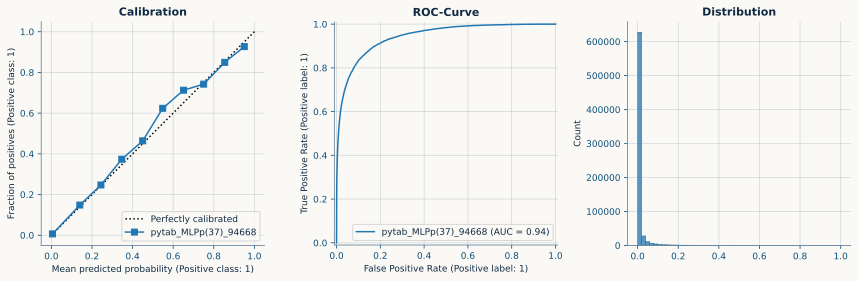

In [15]:
## -- Plot oof distributions --
_, axs = plt.subplots(1, 3, figsize=(12, 4)) 
CalibrationDisplay.from_predictions(y, oof_preds, n_bins=10, name=n, ax=axs[0])
axs[0].set_title(f"Calibration")

RocCurveDisplay.from_predictions(y, oof_preds, name=n, ax=axs[1])
axs[1].set_title(f"ROC-Curve")

sns.histplot(oof_preds, ax=axs[2], bins=50)
axs[2].set_title(f"Distribution")

plt.tight_layout()
plt.show()

print()

In [86]:
# !rm -r /kaggle/working